# Grammar Scoring Engine for Spoken English

**Task.** Given a 45–60 s recording of someone speaking, predict their **grammar score (0–5)**, the MOS Likert rating given by human raters (rubric: 1 = struggles with basic structure … 5 = accurate, complex grammar, self-corrects).
**Data.** 769 labelled training clips, 216 test clips. **Leaderboard metrics:** Pearson correlation and RMSE.

### Approach in one paragraph
With only ~730 usable examples, training a deep network end-to-end would memorise the data. Instead, large **pretrained models are used as frozen "measuring instruments"** and a small regressor learns how the human raters weigh those measurements:

```
              ┌─ Whisper large-v3 (verbatim prompt) ─► transcript + word timings + confidence ─┐
              ├─ wav2vec2 (CTC, no language model) ─► literal transcript ("how clear was it") ─┤
 .wav ─► QC & ─┼─ WavLM-base / WavLM-large ─────────► acoustic embeddings ─────────────────────┼─► 6 feature groups ─► stacked ensemble ─► score
   preprocess  ├─ Whisper-large-v3 encoder ─────────► acoustic embedding ──────────────────────┤   (45 numbers +        (SVR per embedding,
              └─ transcript ─► Qwen2.5-7B + rubric ─► LLM examiner's grade ────────────────────┘    5 embeddings)        then LightGBM + Ridge)
```

| Feature group | What it measures | Rubric link |
|---|---|---|
| **A. Fluency & ASR confidence** | pauses, speed, fillers, restarts, how sure the speech models were | "incomplete sentences", "self-corrects" |
| **B. Syntax & vocabulary** (spaCy) | sentence length, parse-tree depth, subordinate clauses, tense variety, word rarity | "complex grammar structures" |
| **C. Grammar models** | edits a grammar-correction model makes · CoLA acceptability · GPT-2 surprise | "grammatical mistakes", "accuracy" |
| **D. Text embeddings** | overall content/style of the transcript (Whisper and wav2vec2 versions) | holistic |
| **E. Audio embeddings** (WavLM-base, WavLM-large, Whisper encoder) | how the speech sounds | holistic, robust to transcription errors |
| **F. LLM examiner** (v3) | an open LLM's 1-5 grade given SHL's rubric + the transcript | the rubric itself |

**Version history (leaderboard):** v1 = groups A-E with WavLM-base · v2 = + WavLM-large and Whisper encoder · v3 = + LLM examiner, SVR at level 1, and a one-SVR simple model reported alongside · v4 = + 10-second window embeddings (about 10 per clip) modelled by a window-level SVR.

Results, ablations and limitations are summarised in **Section 9**. Every number in this notebook comes from **repeated, stratified 5-fold cross-validation**; the required **training RMSE** is reported next to it.

**Run:** Kaggle → GPU T4, Internet on → *Save & Run All*. With the cached transcripts attached (see 4.2) the whole notebook takes ~30 min; from scratch, add ~70 min of transcription.

## 0. Setup

In [1]:
!pip install -q faster-whisper jiwer sentence-transformers wordfreq bitsandbytes accelerate   # bitsandbytes: 4-bit LLM (5G); installed first so transformers detects it
import spacy
try:
    spacy.load("en_core_web_sm")
except OSError:
    !python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 90.5 MB/s eta 0:00:00


In [2]:
import os, re, gc, glob, json, time, random, difflib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, sosfiltfilt, welch
from scipy.stats import pearsonr
from IPython.display import Audio, display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
SR = 16_000

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED)
except ImportError:
    torch, DEVICE = None, "cpu"
print("device:", DEVICE)

device: cuda


In [3]:
def find_file(name, roots=(os.environ.get("SHL_DATA", ""), "/kaggle/input", "/kaggle/working", ".")):
    for r in roots:
        if r and Path(r).exists():
            hits = sorted(glob.glob(f"{r}/**/{name}", recursive=True))
            if hits:
                return Path(hits[0])
    return None

def find_audio_dir(root, split):
    for d in [root / split, root / "audios" / split, *root.rglob(split)]:
        if Path(d).is_dir() and any(Path(d).glob("*.wav")):
            return Path(d)
    raise FileNotFoundError(f"no {split} audio folder under {root}")

_csv = find_file("train.csv")
if _csv is None:
    attached = sorted(glob.glob("/kaggle/input/*/*"))[:30]
    raise FileNotFoundError("train.csv not found. Attach the competition data (right panel -> Input -> Add Input). "
                            f"Currently attached: {attached or 'nothing'}")
DATA = _csv.parent
AUDIO_DIR = {s: find_audio_dir(DATA, s) for s in ("train", "test")}
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "\naudio:", AUDIO_DIR, "\nwork:", WORK)

data: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final 
audio: {'train': PosixPath('/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train'), 'test': PosixPath('/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test')} 
work: /kaggle/working


## 1. The data

Two quirks found while exploring:
* Train and test **reuse file names for different recordings** (`train/audio_0.wav` ≠ `test/audio_0.wav`), so files are always addressed as *(split, filename)*.
* `sample_submission.csv` lists names that don't match the test folder; **`test.csv` defines the rows to predict** (the submission file follows its order and the sample's columns).

(769, 5) (216, 5)
file names shared by train and test: 212


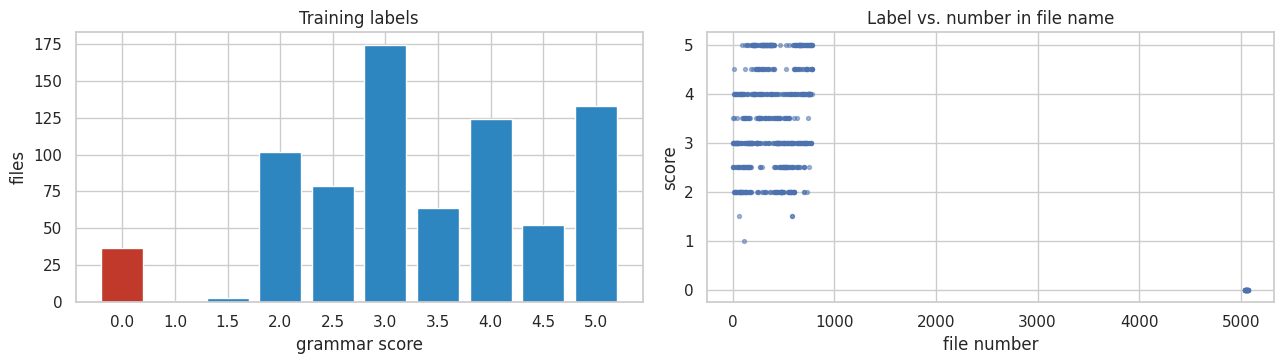

In [4]:
train_df = pd.read_csv(DATA / "train.csv").assign(split="train")
test_df  = pd.read_csv(DATA / "test.csv").assign(split="test")
for df in (train_df, test_df):
    df["path"] = [str(AUDIO_DIR[s] / f) for s, f in zip(df.split, df.filename)]
    df["file_no"] = df.filename.str.extract(r"(\d+)", expand=False).astype(int)
print(train_df.shape, test_df.shape)
print("file names shared by train and test:", len(set(train_df.filename) & set(test_df.filename)))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
vc = train_df.label.value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=["#c0392b" if v == 0 else "#2e86c1" for v in vc.index])
ax[0].set(title="Training labels", xlabel="grammar score", ylabel="files")
ax[1].scatter(train_df.file_no, train_df.label, s=8, alpha=.5)
ax[1].set(title="Label vs. number in file name", xlabel="file number", ylabel="score")
plt.tight_layout(); plt.show()

* Half-point scores (averages of several raters) → a **continuous target → regression**.
* Very few scores below 2 (4 files): little evidence for the bottom of the scale.
* **37 files are scored 0**, a value the rubric doesn't define, and all are numbered `audio_5037`–`audio_5073`, a block the test set (`audio_0`–`audio_215`) never draws from.

## 2. Audio quality check: what are the score-0 files?

Cheap signal statistics per file: **SNR estimate** (loud vs. quiet frames: speech with pauses → large gap) and **spectral flatness** (~0 for voiced speech, ~1 for white noise).

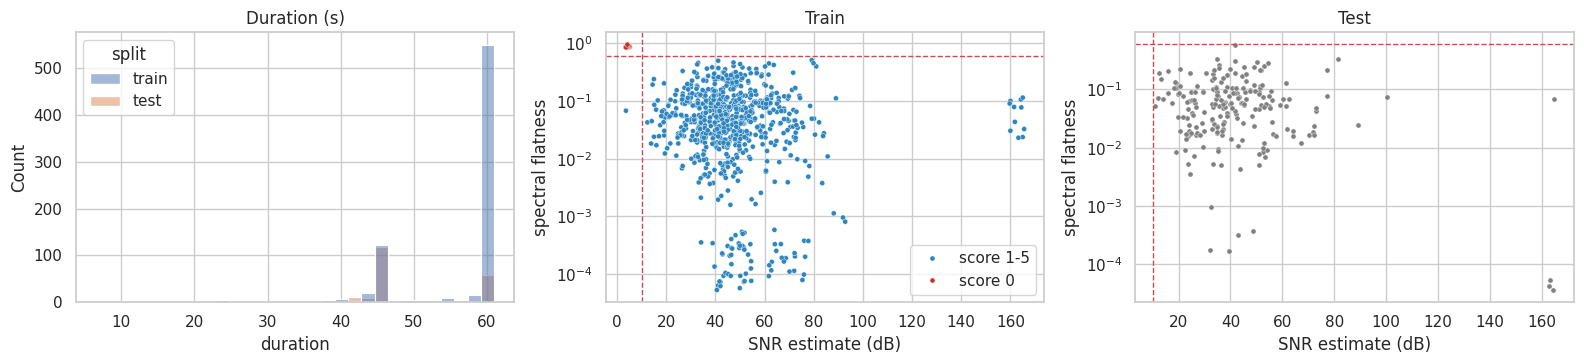

label is 0        False  True 
flagged as noise              
False               732      0
True                  0     37
test files flagged as noise: 0


In [5]:
def audio_stats(path):
    x, sr = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(1)
    fl = int(0.025 * sr)
    db = 20 * np.log10(np.sqrt((x[: len(x) // fl * fl].reshape(-1, fl) ** 2).mean(1)) + 1e-9)
    _, P = welch(x, sr, nperseg=1024)
    return dict(sr=sr, duration=len(x) / sr, rms_db=20 * np.log10(np.sqrt((x ** 2).mean()) + 1e-9),
                snr_est_db=np.percentile(db, 95) - np.percentile(db, 10),
                flatness=float(np.exp(np.mean(np.log(P + 1e-20))) / np.mean(P)))

p = WORK / "audio_stats.csv"
if p.exists():
    stats = pd.read_csv(p)
else:
    allf = pd.concat([train_df, test_df], ignore_index=True)
    stats = pd.DataFrame([audio_stats(x) for x in allf.path]).assign(split=allf.split.values, filename=allf.filename.values)
    stats.to_csv(p, index=False)
train_df = train_df.merge(stats, on=["split", "filename"]); test_df = test_df.merge(stats, on=["split", "filename"])

# Noise rule = BOTH signals must agree. Score-0 files: flatness 0.84-0.96 AND SNR 3.5-5.1 dB.
# Either signal alone misfires on real speech: some speech has flatness up to 0.51 (near-silent pauses),
# some has SNR down to 3.6 dB (steady background hum), but no speech file has both.
NOISE_FLATNESS, NOISE_SNR_DB = 0.6, 10
for df in (train_df, test_df): df["is_noise"] = (df.flatness > NOISE_FLATNESS) & (df.snr_est_db < NOISE_SNR_DB)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(stats, x="duration", hue="split", bins=30, ax=ax[0]); ax[0].set_title("Duration (s)")
grp = np.where(train_df.label == 0, "score 0", "score 1-5")
sns.scatterplot(x=train_df.snr_est_db, y=train_df.flatness, hue=grp, palette={"score 0": "#c0392b", "score 1-5": "#2e86c1"}, s=14, ax=ax[1])
sns.scatterplot(x=test_df.snr_est_db, y=test_df.flatness, color="gray", s=14, ax=ax[2])
ax[1].set_title("Train"); ax[2].set_title("Test")
for a in ax[1:]: a.set(yscale="log", xlabel="SNR estimate (dB)", ylabel="spectral flatness"); a.axvline(NOISE_SNR_DB, c="r", ls="--", lw=1); a.axhline(NOISE_FLATNESS, c="r", ls="--", lw=1)
plt.tight_layout(); plt.show()
print(pd.crosstab(train_df.is_noise, train_df.label == 0, rownames=["flagged as noise"], colnames=["label is 0"]))
print("test files flagged as noise:", int(test_df.is_noise.sum()))

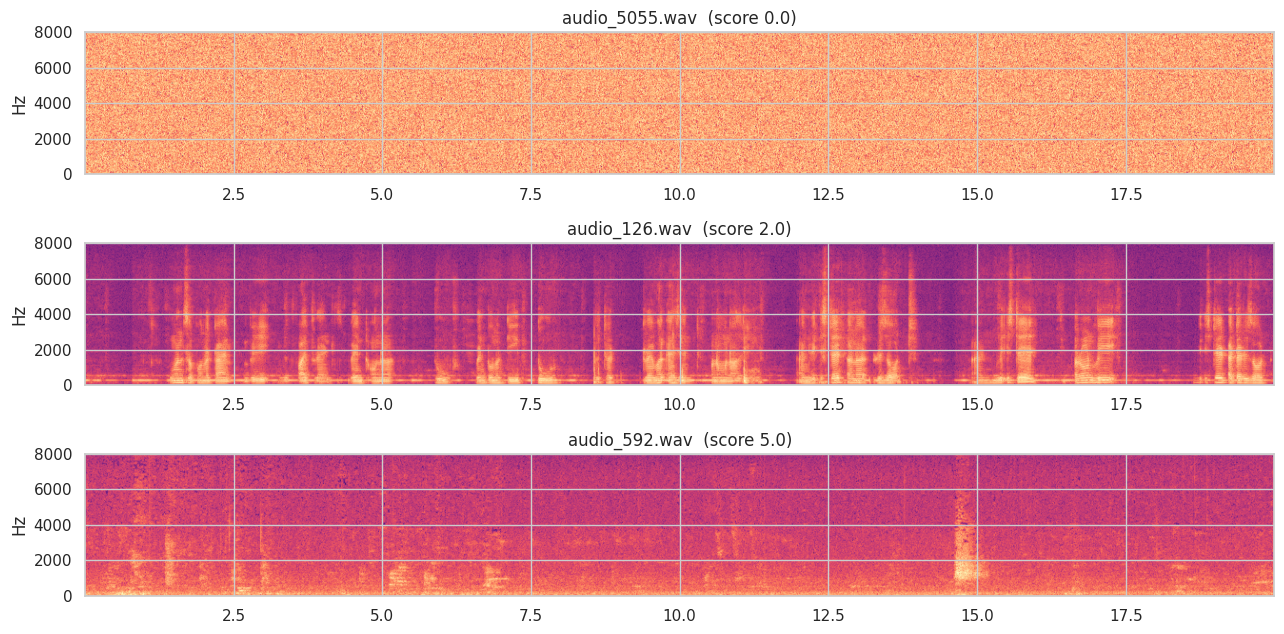

In [6]:
ex = [train_df[train_df.label == 0].iloc[0], train_df[train_df.label == 2].iloc[0], train_df[train_df.label == 5].iloc[0]]
fig, ax = plt.subplots(3, 1, figsize=(13, 6.5))
for a, r in zip(ax, ex):
    x, _ = sf.read(r.path); a.specgram(x[: SR * 20], Fs=SR, NFFT=512, noverlap=256, cmap="magma")
    a.set(title=f"{r.filename}  (score {r.label})", ylabel="Hz")
plt.tight_layout(); plt.show()

**Finding.** The score-0 files are buried in broadband static; speech is faint or absent. They form a separate cluster, **high flatness and low SNR at the same time** (top-left box between the red lines), that **no test file falls into**.
Neither measure alone is safe: some real speech has high flatness (near-silent pauses) and some has low SNR (steady background hum), but none has both. A first version of this rule used flatness only and wrongly discarded 30 speech files; requiring both signals fixed it.

**Decision.** These 37 files are **excluded from training and cross-validation**:
1. The test set contains none, so they say nothing about test performance.
2. "Static → 0" is trivially learnable and would inflate Pearson without teaching anything about grammar (quantified in 7.4).
3. Whisper *hallucinates* fluent text on pure noise (example in 4.3); its "grammar" there is meaningless.

The flatness rule stays as a safety net when predicting.

## 3. Preprocessing

Kept deliberately light, since modern speech models are trained on noisy audio and denoising artifacts tend to hurt them more than the noise.
1. **Mono, 16 kHz** (the format every model here expects).
2. **High-pass filter at 70 Hz**: removes hum and rumble, which carry no speech information.
3. **Loudness normalisation** to −20 dBFS RMS with a peak guard (recordings differ by ~20 dB).
4. **Silence:** handled by Whisper's built-in **voice-activity detector** during transcription rather than cut out of the audio, so pause lengths remain measurable as fluency features.

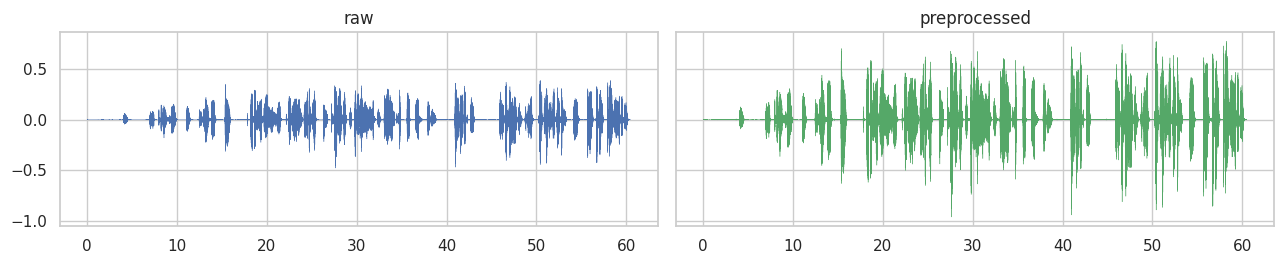

In [7]:
_HPF = butter(4, 70, btype="highpass", fs=SR, output="sos")

def load_audio(path, target_dbfs=-20.0):
    x, sr = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(1)
    if sr != SR: x = librosa.resample(x, orig_sr=sr, target_sr=SR)
    x = sosfiltfilt(_HPF, x).astype(np.float32)
    x *= 10 ** (target_dbfs / 20) / (np.sqrt(np.mean(x ** 2)) + 1e-9)
    peak = np.abs(x).max()
    return x * (0.99 / peak) if peak > 0.99 else x

r = train_df[~train_df.is_noise].iloc[0]
raw, _ = sf.read(r.path); pre = load_audio(r.path)
fig, ax = plt.subplots(1, 2, figsize=(13, 2.8), sharey=True)
ax[0].plot(np.arange(len(raw)) / SR, raw, lw=.3); ax[0].set_title("raw")
ax[1].plot(np.arange(len(pre)) / SR, pre, lw=.3, color="g"); ax[1].set_title("preprocessed")
plt.tight_layout(); plt.show()

## 4. Speech to text

### 4.1 Choosing the transcriber: an experiment, not an assumption
Grammar has to be judged on what the speaker *actually said*. Two models with opposite risks were compared:

| | **Whisper large-v3** | **wav2vec2-large-960h** (CTC) |
|---|---|---|
| Design | audio encoder + built-in language model | letter-by-letter, no language model |
| Expected risk | may silently "fix" grammar, drop fillers | may mishear, invent non-words |

To counter Whisper's tidying, it is given a **verbatim-style initial prompt** ("Umm, so, I- I was, uh, I go to…").

**Measured on 24 stratified training files** (code below, `RUN_ASR_STUDY=True` to reproduce):

| | Whisper plain | Whisper verbatim prompt | wav2vec2 |
|---|---|---|---|
| words / file | 103.2 | 104.9 | 106.0 |
| fillers kept (total) | 3 | **25** | 2 |
| repetitions kept (total) | 17 | **18** | 4 |

Word error rate between the two Whisper variants: 0.05; between verbatim Whisper and wav2vec2: 0.24.

**Reading the evidence:**
* The prompt does what it should: fillers are kept (3 → 25) while the rest of the transcript barely changes (95 % identical).
* Inspecting the transcripts (4.3), **Whisper keeps genuine grammar errors** ("if a market crowded", "there is a plenty of demand"); it did not rewrite learners into fluent English.
* **wav2vec2 is not "more literal", it is garbled**: non-words such as "fusht", "wory", "jecked", and it drops fillers too (it was trained on read audiobooks).

* **Listening check** on the files where the systems disagreed most confirmed this: plain and prompted Whisper differed mainly in punctuation, while wav2vec2 failed on accented pronunciations and wrote meaningless words instead.

**Decision.** Whisper-verbatim transcripts feed all grammar tools. wav2vec2 is kept as a **clarity signal**: how often it garbles, and how much it disagrees with Whisper, both track how intelligible the speaker is (which correlates with proficiency).

In [8]:
RUN_ASR_STUDY = False          # True: re-run the 24-file comparison above (~5 min GPU)
FILLERS = {"um", "umm", "uh", "uhm", "er", "erm", "ah", "hmm", "mm", "eh"}
VERBATIM_PROMPT = ("Umm, so, I- I was, uh, I go to the market yesterday and, er, I buyed some, "
                   "some vegetable. Hmm, like, you know, it was- it is very crowd.")

def norm_words(t):
    # lowercase word list (letters and apostrophes only), used for counts and error rates
    return re.sub(r"[^a-z' ]+", " ", str(t).lower().replace("-", " ")).split()

_asr = {}
def asr_models():
    # Loaded only when transcription is actually needed.
    if not _asr:
        from faster_whisper import WhisperModel
        from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC
        _asr["whisper"] = WhisperModel("large-v3", device=DEVICE, compute_type="float16")
        name = "facebook/wav2vec2-large-960h-lv60-self"
        _asr["proc"] = Wav2Vec2Processor.from_pretrained(name)
        _asr["w2v"] = Wav2Vec2ForCTC.from_pretrained(name).to(DEVICE).half().eval()
    return _asr

def whisper_transcribe(x, prompt=VERBATIM_PROMPT):
    segs, _ = asr_models()["whisper"].transcribe(
        x, language="en", beam_size=5, initial_prompt=prompt, condition_on_previous_text=False,
        vad_filter=True, vad_parameters=dict(min_silence_duration_ms=500), word_timestamps=True)
    segs = list(segs)
    words = [dict(w=w.word.strip(), s=round(w.start, 2), e=round(w.end, 2), p=round(w.probability, 3))
             for sg in segs for w in (sg.words or [])]
    return dict(text=" ".join(sg.text.strip() for sg in segs),
                avg_logprob=float(np.mean([s.avg_logprob for s in segs])) if segs else -5.0,
                no_speech_prob=float(np.mean([s.no_speech_prob for s in segs])) if segs else 1.0, words=words)

def w2v_transcribe(x, chunk_s=30):
    m = asr_models(); out, conf = [], []
    with torch.no_grad():
        for i in range(0, len(x), chunk_s * SR):
            c = x[i: i + chunk_s * SR]
            if len(c) < SR // 2: continue
            inp = m["proc"](c, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE).half()
            probs = m["w2v"](inp).logits.float().softmax(-1)[0]
            out.append(m["proc"].decode(probs.argmax(-1))); conf.append(probs.max(-1).values.mean().item())
    return dict(w2v_text=" ".join(out).lower(), w2v_conf=float(np.mean(conf)) if conf else 0.0)

if RUN_ASR_STUDY:
    import jiwer
    study = (train_df[~train_df.is_noise].groupby(train_df.label.round().clip(1, 5), group_keys=False)
             .apply(lambda g: g.sample(min(len(g), 5), random_state=SEED)).head(24))
    rows = []
    for r in study.itertuples():
        x = load_audio(r.path)
        t = {"plain": whisper_transcribe(x, None)["text"], "verbatim": whisper_transcribe(x)["text"], "w2v": w2v_transcribe(x)["w2v_text"]}
        rows.append({"filename": r.filename, "label": r.label, **t,
                     **{f"fillers_{k}": sum(w in FILLERS for w in norm_words(v)) for k, v in t.items()},
                     **{f"repeats_{k}": sum(a == b for a, b in zip(norm_words(v), norm_words(v)[1:])) for k, v in t.items()}})
    display(pd.DataFrame(rows).filter(regex="label|fillers|repeats").sum().round(1))

### 4.2 Transcribe all files (or load the cache)
Transcription is the only slow step (~4 s per file on a T4). Results are written one line per file to `transcripts_<split>.jsonl`; a crashed run resumes where it stopped.
**To skip it**, upload the two `.jsonl` files from a previous run as a Kaggle dataset and attach it: the notebook finds them automatically.

Each line holds: Whisper text, every word with start/end time and confidence, Whisper's average log-probability, the wav2vec2 text and its confidence.

In [9]:
def transcribe_split(df, split):
    cached = find_file(f"transcripts_{split}.jsonl")
    out = WORK / f"transcripts_{split}.jsonl"
    if cached is not None and cached.resolve() != out.resolve():
        out.write_text(cached.read_text())                     # copy attached cache into the working dir
    done = {json.loads(l)["filename"] for l in open(out)} if out.exists() else set()
    todo = df[~df.filename.isin(done)]
    print(f"{split}: {len(done)} cached, {len(todo)} to transcribe")
    t0 = time.time()
    with open(out, "a") as f:
        for i, r in enumerate(todo.itertuples(), 1):
            x = load_audio(r.path)
            f.write(json.dumps({"filename": r.filename, **whisper_transcribe(x), **w2v_transcribe(x)}) + "\n"); f.flush()
            if i % 50 == 0: print(f"  {i}/{len(todo)}  {(time.time() - t0) / i:.1f}s per file")
    tx = pd.read_json(out, lines=True).drop_duplicates("filename")
    assert set(df.filename) <= set(tx.filename), "some files are missing a transcript"
    return tx

train_df = train_df.merge(transcribe_split(train_df, "train"), on="filename", how="left")
test_df  = test_df.merge(transcribe_split(test_df, "test"), on="filename", how="left")
if _asr: del _asr["whisper"], _asr["w2v"]; gc.collect(); torch.cuda.empty_cache()   # free GPU for later models

train: 769 cached, 0 to transcribe
test: 216 cached, 0 to transcribe


### 4.3 What the transcripts look like

In [10]:
def show(r, n=420):
    print(f"── {r.filename}  score {r.label}\n  Whisper : {r.text[:n]}\n  wav2vec2: {r.w2v_text[:n * 2 // 3]}\n")

for sc in [2.0, 3.0, 4.0, 5.0]:
    show(train_df[(train_df.label == sc) & ~train_df.is_noise].iloc[0])
print("A noise-only file (excluded). Whisper invents fluent text; wav2vec2 outputs almost nothing:")
show(train_df[train_df.is_noise].iloc[0])

── audio_126.wav  score 2.0
  Whisper : Once upon a time, we, with five friends, went on a tour, went on a deep tour with a travel agent on a Manali, and we stayed in a resort, and we stayed around, we stayed at a resort, and after that, in staying, when we checked in in the resort, after that, at night, we played with you, you know, you know, we played, and after that, we went on the floor top to see the night view of the resort. Manali and to enjoy the n
  wav2vec2: once upon a time we with five friends went on a to wentonty to with a treveesent phenomenal and we stared ona resort and we stared around we we stared at a resort and after at istint when we jecked in in the resort after that at night we played with yo ouno onore flay and after t

── audio_192.wav  score 3.0
  Whisper : Um, well, this- the playground is very, very beautiful and fun. There are- there are playtools like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, um, it's more lik

## 5. Features

Before the grammar tools see a transcript it is **cleaned of hesitations** (fillers, cut-off fragments like "I w- I", stuttered repeats). Hesitations are measured separately as fluency features, and grammar checkers would otherwise count every "um" as an error.

In [11]:
def clean_for_grammar(t):
    t = re.sub(r"\b(" + "|".join(FILLERS) + r")\b[,.]?\s*", "", str(t), flags=re.I)   # fillers
    t = re.sub(r"\b[\w']+-\s+", "", t)                                                 # abandoned fragments "w- ", "many- "
    t = re.sub(r"\b(\w+)(\s+\1\b)+", r"\1", t, flags=re.I)                            # "the the" -> "the"
    return re.sub(r"\s+([,.!?])", r"\1", re.sub(r"\s{2,}", " ", t)).strip()

for df in (train_df, test_df): df["clean"] = df.text.fillna("").map(clean_for_grammar)
r = train_df.iloc[3]; print("RAW  :", r.text[:300]); print("CLEAN:", r.clean[:300])

RAW  : Once upon a time, we, with five friends, went on a tour, went on a deep tour with a travel agent on a Manali, and we stayed in a resort, and we stayed around, we stayed at a resort, and after that, in staying, when we checked in in the resort, after that, at night, we played with you, you know, you 
CLEAN: Once upon a time, we, with five friends, went on a tour, went on a deep tour with a travel agent on a Manali, and we stayed in a resort, and we stayed around, we stayed at a resort, and after that, in staying, when we checked in the resort, after that, at night, we played with you, you know, you kno


### 5A. Fluency & ASR confidence
* **Speaking:** words, words per minute, mean pause, pauses > 1 s, speech duration.
* **Hesitation:** filler rate, repeated-word rate, **fragment rate** (abandoned words like "w-": restarts and self-corrections).
* **Confidence:** Whisper's average log-probability, mean word probability, share of low-confidence words, wav2vec2 confidence.
* **Clarity:** share of non-words in the wav2vec2 transcript, word error rate between the two transcripts (more disagreement suggests less intelligible speech).

In [12]:
import jiwer
from wordfreq import zipf_frequency       # how common a word is: 7 = "the", 1 = very rare / not a word

def fluency_features(r):
    words = r["words"] if isinstance(r["words"], list) else []
    w, w2 = norm_words(r["text"]), norm_words(r["w2v_text"]); n = max(len(w), 1)
    if len(words) > 1:
        span = words[-1]["e"] - words[0]["s"]
        gaps = np.array([b["s"] - a["e"] for a, b in zip(words, words[1:])]).clip(0)
        probs = np.array([x["p"] for x in words])
    else:
        span, gaps, probs = 0.0, np.zeros(1), np.zeros(1)
    return dict(
        n_words=len(w), words_per_min=60 * len(w) / max(span, 1.0), speech_span_s=span,
        mean_pause_s=float(gaps.mean()), long_pauses=int((gaps > 1.0).sum()),
        filler_rate=sum(x in FILLERS for x in w) / n,
        repeat_rate=sum(a == b for a, b in zip(w, w[1:])) / n,
        fragment_rate=len(re.findall(r"\b\w+-(?=\s|$)", str(r["text"]))) / n,
        avg_logprob=r["avg_logprob"], mean_word_prob=float(probs.mean()),
        low_conf_word_rate=float((probs < 0.5).mean()), w2v_conf=r["w2v_conf"],
        w2v_nonword_rate=float(np.mean([zipf_frequency(x, "en") < 1.5 for x in w2]) if w2 else 1.0),
        asr_disagreement=jiwer.wer(" ".join(w), " ".join(w2)) if w and w2 else 1.0)

F_flu = {s: pd.DataFrame([fluency_features(r) for r in df.to_dict("records")]) for s, df in [("train", train_df), ("test", test_df)]}

### 5B. Syntax & vocabulary (spaCy dependency parser)
The parser draws each sentence as a tree of which word depends on which. From it:
* **Structure:** sentences, mean/max sentence length, mean/max **tree depth** (nesting), **subordinate clauses per sentence** ("because…", "which…", "that…"), share of sentences with **no verb** (fragments).
* **Grammar range:** number of distinct tenses and verb forms used; rates of verbs, auxiliaries, determiners, pronouns, adjectives/adverbs, conjunctions.
* **Vocabulary:** mean word commonness, rare-word rate, distinct-word ratios.

In [13]:
nlp = spacy.load("en_core_web_sm")
SUBORD = {"mark", "advcl", "ccomp", "relcl", "acl", "xcomp", "csubj"}

def tree_depth(tok):
    d = 0
    while tok.head.i != tok.i:          # compare positions: spaCy creates new token objects on each access
        tok, d = tok.head, d + 1
    return d

SYN_KEYS = ["n_sents", "mean_sent_len", "max_sent_len", "mean_tree_depth", "max_tree_depth", "subord_rate",
            "sents_without_verb", "tense_variety", "verb_rate", "aux_rate", "det_rate", "pron_rate", "adj_adv_rate",
            "conj_rate", "mean_word_zipf", "rare_word_rate", "type_token_ratio", "lemma_variety"]

def syntax_features(doc):
    sents = [s for s in doc.sents if any(t.is_alpha for t in s)]
    toks = [t for t in doc if t.is_alpha]; n = max(len(toks), 1)
    if not sents: return dict.fromkeys(SYN_KEYS, 0.0)
    slen = [sum(t.is_alpha for t in s) for s in sents]
    depth = [max(tree_depth(t) for t in s) for s in sents]
    forms = {m for t in doc for m in t.morph.get("Tense")} | {m for t in doc for m in t.morph.get("VerbForm") if m in {"Part", "Ger"}}
    z = [zipf_frequency(t.lower_, "en") for t in toks]
    pos = lambda *p: sum(t.pos_ in p for t in toks) / n
    return dict(n_sents=len(sents), mean_sent_len=np.mean(slen), max_sent_len=max(slen),
                mean_tree_depth=np.mean(depth), max_tree_depth=max(depth),
                subord_rate=sum(t.dep_ in SUBORD for t in doc) / len(sents),
                sents_without_verb=np.mean([not any(t.pos_ in {"VERB", "AUX"} for t in s) for s in sents]),
                tense_variety=len(forms), verb_rate=pos("VERB"), aux_rate=pos("AUX"), det_rate=pos("DET"),
                pron_rate=pos("PRON"), adj_adv_rate=pos("ADJ", "ADV"), conj_rate=pos("CCONJ", "SCONJ"),
                mean_word_zipf=np.mean(z), rare_word_rate=np.mean([v < 4 for v in z]),
                type_token_ratio=len({t.lower_ for t in toks}) / n, lemma_variety=len({t.lemma_ for t in toks}) / n)

docs = {s: list(nlp.pipe(df.clean.tolist(), batch_size=64)) for s, df in [("train", train_df), ("test", test_df)]}
F_syn = {s: pd.DataFrame([syntax_features(d) for d in docs[s]]) for s in docs}

# sentence lists for the grammar models; very long run-on "sentences" are split into <=40-word pieces
def sentence_list(doc, max_words=40):
    out = []
    for s in doc.sents:
        w = s.text.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return [s for s in out if len(norm_words(s)) >= 2] or ["(no speech)"]
SENTS = {s: [sentence_list(d) for d in docs[s]] for s in docs}

### 5C. Grammar models (GPU)
Three pretrained models, each run sentence by sentence on the cleaned Whisper transcript:
1. **Grammatical-error correction** (`vennify/t5-base-grammar-correction`): rewrites each sentence into correct English. Counting the words it had to **insert / delete / replace** gives an error density: the most direct measure of "grammatical mistakes".
2. **CoLA acceptability** (`textattack/roberta-base-CoLA`): a classifier trained on the *Corpus of Linguistic Acceptability* gives each sentence a 0–1 "is this grammatical English?" probability → mean, minimum, share below 0.5.
3. **GPT-2 surprise (perplexity)**: how unexpected each sentence is to a language model; broken syntax is surprising. Mean and worst sentence, in log units.

Each block is cached to disk and wrapped so that a failed model download skips that block rather than stopping the notebook.

In [14]:
def cached_block(name, fn):
    # Load features from cache, else compute them; on failure warn and return None (block skipped).
    p = WORK / f"feat_{name}.pkl"
    if not p.exists() and find_file(p.name) is not None:     # cache from an earlier run attached as a dataset
        p = find_file(p.name)
    if p.exists(): return pd.read_pickle(p)
    try:
        t0 = time.time(); out = fn(); pd.to_pickle(out, p)
        print(f"{name}: computed in {time.time() - t0:.0f}s"); return out
    except Exception as e:
        print(f"!! {name} skipped: {type(e).__name__}: {str(e)[:200]}"); return None
    finally:
        gc.collect()
        if torch is not None and DEVICE == "cuda": torch.cuda.empty_cache()

def flat(split):
    # all sentences of a split as one list + the file index each belongs to
    s = SENTS[split]; return [x for f in s for x in f], np.repeat(np.arange(len(s)), [len(f) for f in s])

def batched(fn, items, bs=32):
    order = np.argsort([len(x) for x in items]); out = [None] * len(items)   # length-sorted batches = less padding
    for i in range(0, len(items), bs):
        idx = order[i:i + bs]
        for j, v in zip(idx, fn([items[k] for k in idx])): out[j] = v
    return out

def edit_counts(src, hyp):
    a, b = norm_words(src), norm_words(hyp); ins = dele = rep = 0
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes():
        if op == "replace": rep += max(i2 - i1, j2 - j1)
        elif op == "delete": dele += i2 - i1
        elif op == "insert": ins += j2 - j1
    return ins, dele, rep, len(a)

def gec_block():
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    name = "vennify/t5-base-grammar-correction"
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSeq2SeqLM.from_pretrained(name).to(DEVICE).eval()     # fp32: T5 is unstable in fp16
    @torch.no_grad()
    def correct(batch):
        enc = tok(["grammar: " + s for s in batch], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        return tok.batch_decode(model.generate(**enc, num_beams=4, max_new_tokens=128), skip_special_tokens=True)
    res = {}
    for split in SENTS:
        sents, fid = flat(split); corr = batched(correct, sents)
        e = pd.DataFrame([edit_counts(s, c) for s, c in zip(sents, corr)], columns=["ins", "del", "rep", "n"])
        e["fid"], e["changed"] = fid, (e[["ins", "del", "rep"]].sum(1) > 0)
        e["rate"] = e[["ins", "del", "rep"]].sum(1) / e.n.clip(lower=1)
        g = e.groupby("fid"); n = g.n.sum().clip(lower=1)
        res[split] = pd.DataFrame({
            "gec_edits_per_100w": 100 * g[["ins", "del", "rep"]].sum().sum(1) / n,
            "gec_insert_per_100w": 100 * g.ins.sum() / n, "gec_delete_per_100w": 100 * g["del"].sum() / n,
            "gec_replace_per_100w": 100 * g.rep.sum() / n,
            "gec_sents_changed": g.changed.mean(), "gec_worst_sent_rate": g.rate.max()}).reset_index(drop=True)
        res[split + "_examples"] = list(zip(sents, corr, fid))
    return res

def cola_block():
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    name = "textattack/roberta-base-CoLA"
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(name).to(DEVICE).eval()
    @torch.no_grad()
    def score(batch):
        enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        return model(**enc).logits.float().softmax(-1)[:, 1].cpu().numpy().tolist()   # label 1 = acceptable
    res = {}
    for split in SENTS:
        sents, fid = flat(split)
        d = pd.DataFrame({"p": batched(score, sents, 64), "fid": fid}).groupby("fid").p
        res[split] = pd.DataFrame({"cola_mean": d.mean(), "cola_min": d.min(),
                                   "cola_share_bad": d.apply(lambda v: (v < .5).mean())}).reset_index(drop=True)
    return res

def ppl_block():
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained("gpt2"); tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()
    @torch.no_grad()
    def nll(batch):
        enc = tok([tok.bos_token + s for s in batch], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        logits = model(**enc).logits[:, :-1].float()
        tgt, mask = enc.input_ids[:, 1:], enc.attention_mask[:, 1:].float()
        tok_nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), tgt, reduction="none")
        return ((tok_nll * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu().numpy().tolist()  # mean surprise per token
    res = {}
    for split in SENTS:
        sents, fid = flat(split)
        d = pd.DataFrame({"v": batched(nll, sents, 64), "fid": fid}).groupby("fid").v
        res[split] = pd.DataFrame({"gpt2_surprise_mean": d.mean(), "gpt2_surprise_max": d.max()}).reset_index(drop=True)
    return res

GEC, COLA, PPL = cached_block("gec", gec_block), cached_block("cola", cola_block), cached_block("gpt2", ppl_block)

In [15]:
# What the correction model changes, on a low-scored training file.
if GEC is not None:
    low = int(np.argmin(train_df.label.where(~train_df.is_noise, 9).values))
    print(f"{train_df.filename[low]}  (score {train_df.label[low]})")
    for s, c, f in GEC["train_examples"]:
        if f == low and s != c: print(f"  said     : {s}\n  corrected: {c}\n")

audio_108.wav  (score 1.0)
  said     : As a young child, one of the most exciting place to be was the playground.
  corrected: As a young child, one of the most exciting places to be was the playground.

  said     : It was a place where the rules of classrooms and the structure environment of schools has been, played well in our, like, the school days.
  corrected: It was a place where the rules of classrooms and the structure environment of schools have been, played well in our, like, school days.

  said     : We need to play very good, sport in our playgrounds and we had lots of injuries in that our school time.
  corrected: We need to play very good, sport in our playgrounds and we had lots of injuries during our school time.

  said     : We need to play all the things what we need to know about the things that we need to know.
  corrected: We need to play all the things that we need to know about the things that we need to know.



### 5D–E. Embeddings
* **Text** (`all-mpnet-base-v2`): each transcript becomes 768 numbers summarising its content and style. Computed for the Whisper text and, separately, the wav2vec2 text (which also encodes how garbled the speech was).
* **Audio** (`microsoft/wavlm-base-plus`, layer 8, averaged over time): 768 numbers describing how the speech *sounds*. These don't depend on the transcription at all.

768 columns would swamp 600 training rows, so each embedding is first turned into **one number**: a Ridge model's prediction of the score (Section 6, "stacking").

In [16]:
def text_emb_block():
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=DEVICE)
    enc = lambda t: m.encode([x if str(x).strip() else "(silence)" for x in t], batch_size=32, normalize_embeddings=True)
    return {f"{col}_{s}": enc(df[col].fillna("").tolist()) for s, df in [("train", train_df), ("test", test_df)] for col in ("text", "w2v_text")}

def wavlm_block():
    from transformers import AutoFeatureExtractor, WavLMModel
    name = "microsoft/wavlm-base-plus"
    fe = AutoFeatureExtractor.from_pretrained(name); model = WavLMModel.from_pretrained(name).to(DEVICE).eval()
    @torch.no_grad()
    def emb(x, layer=8, chunk_s=20):
        e, w = [], []
        for i in range(0, len(x), chunk_s * SR):
            c = x[i: i + chunk_s * SR]
            if len(c) < SR: continue
            h = model(fe(c, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE), output_hidden_states=True).hidden_states[layer][0]
            e.append(h.mean(0).float().cpu().numpy()); w.append(h.shape[0])
        return np.average(e, axis=0, weights=w) if e else np.zeros(768, dtype=np.float32)
    return {s: np.stack([emb(load_audio(p)) for p in df.path]) for s, df in [("train", train_df), ("test", test_df)]}

TXT, WAV = cached_block("text_emb", text_emb_block), cached_block("wavlm", wavlm_block)

### 5F. Stronger audio models (added after the first leaderboard submission)
The ablation (7.3) showed the audio embedding carries most of the signal, so the natural next step is a **better audio model**. Two are added:
* **WavLM-large**: the same family as WavLM-base, but about 3× larger (24 layers, 1024 numbers per layer) and trained on far more speech.
* **Whisper-large-v3's encoder**: the "listening" half of the speech recogniser used for transcription (32 layers, 1280 numbers). It was trained on 5 million hours of multilingual speech, so it has learned a lot about accents and fluency.

A deep model's **layers** hold different information: early layers capture raw sound, middle layers pronunciation and phonetics, late layers words and meaning. Instead of guessing, every layer is averaged over time and saved, and 6.1 measures which layer best predicts the grammar score.

In [17]:
def wavlm_large_block():
    from transformers import AutoFeatureExtractor, WavLMModel
    name = "microsoft/wavlm-large"
    fe = AutoFeatureExtractor.from_pretrained(name)
    model = WavLMModel.from_pretrained(name).to(DEVICE).half().eval()
    @torch.no_grad()
    def emb(x, chunk_s=20):
        e, w = [], []
        for i in range(0, len(x), chunk_s * SR):
            c = x[i: i + chunk_s * SR]
            if len(c) < SR: continue
            inp = fe(c, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE).half()
            hs = model(inp, output_hidden_states=True).hidden_states            # 25 tensors: input + 24 layers
            e.append(np.stack([h[0].float().mean(0).cpu().numpy() for h in hs])); w.append(hs[0].shape[1])
        return np.average(e, axis=0, weights=w).astype(np.float16) if e else np.zeros((25, 1024), np.float16)
    return {s: np.stack([emb(load_audio(p)) for p in df.path]) for s, df in [("train", train_df), ("test", test_df)]}

def whisper_enc_block():
    from transformers import WhisperFeatureExtractor, WhisperModel
    name = "openai/whisper-large-v3"
    fe = WhisperFeatureExtractor.from_pretrained(name)
    enc = WhisperModel.from_pretrained(name, torch_dtype=torch.float16).encoder.to(DEVICE).eval()
    @torch.no_grad()
    def emb(x, chunk_s=30):
        e, w = [], []
        for i in range(0, len(x), chunk_s * SR):
            c = x[i: i + chunk_s * SR]
            if len(c) < SR: continue
            feats = fe(c, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE).half()   # padded to 30 s
            n = max(1, int(len(c) / SR * 50))                                   # encoder frames that hold real audio (50 per second)
            hs = enc(feats, output_hidden_states=True).hidden_states           # 33 tensors: input + 32 layers
            e.append(np.stack([h[0, :n].float().mean(0).cpu().numpy() for h in hs])); w.append(n)
        return np.average(e, axis=0, weights=w).astype(np.float16) if e else np.zeros((33, 1280), np.float16)
    return {s: np.stack([emb(load_audio(p)) for p in df.path]) for s, df in [("train", train_df), ("test", test_df)]}

WAVL, WENC = cached_block("wavlm_large", wavlm_large_block), cached_block("whisper_enc", whisper_enc_block)
for n, b in [("WavLM-large", WAVL), ("Whisper encoder", WENC)]:
    if b is not None: print(n, "per-layer embeddings:", b["train"].shape)

WavLM-large per-layer embeddings: (769, 25, 1024)
Whisper encoder per-layer embeddings: (769, 33, 1280)


### 5G. An LLM examiner as one more feature (added in v3)
The text features so far measure grammar *indirectly* (edits, acceptability, surprise), and the ablation showed they add little on top of audio. A large language model can read a transcript the way a human examiner reads it. So an open-source instruction-tuned LLM (**Qwen2.5-7B-Instruct**, run on the GPU in 4-bit, no paid API) is shown **SHL's rubric and the transcript** and asked which score from 1 to 5 fits.

Instead of reading a generated answer, the model's **probabilities for the five digits** are read directly: the expected value of the score, sum of k times P(k), gives a continuous grade (e.g. 3.4), and the largest probability says how sure it is. These two numbers form group **F**. The LLM never sees the training labels: it is a measuring instrument like the others, and the regressor learns how much to trust it.

LLM used: Qwen/Qwen2.5-7B-Instruct | correlation of llm_grade with the human score: 0.544


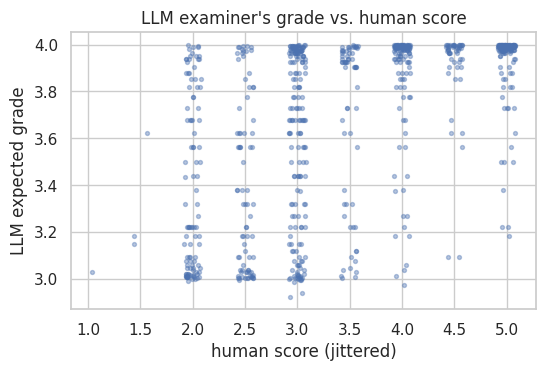

In [18]:
RUBRIC = ("Grammar score rubric (1-5):\n"
    "1: The speech struggles with proper sentence structure and syntax, displaying limited control over simple grammatical structures and memorized sentence patterns.\n"
    "2: Limited understanding of sentence structure and syntax. Uses simple structures but consistently makes basic sentence structure and grammatical mistakes. Might leave sentences incomplete.\n"
    "3: A decent grasp of sentence structure but errors in grammatical structure, or a decent grasp of grammatical structure but errors in sentence syntax and structure.\n"
    "4: A strong understanding of sentence structure and syntax. Consistently good control of grammar. Occasional errors are minor, do not lead to misunderstandings, and most are corrected.\n"
    "5: High grammatical accuracy and adept control of complex grammar. Uses grammar accurately and effectively, seldom making noticeable mistakes. Handles complex structures well and self-corrects when necessary.")

def llm_block():
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    name = "Qwen/Qwen2.5-7B-Instruct"
    try:
        tok = AutoTokenizer.from_pretrained(name)
        model = AutoModelForCausalLM.from_pretrained(name, device_map="cuda:0", quantization_config=BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16))
    except Exception as e:                       # fallback: smaller model in plain fp16, no bitsandbytes needed
        print("7B in 4-bit unavailable, using Qwen2.5-3B-Instruct:", str(e)[:200])
        name = "Qwen/Qwen2.5-3B-Instruct"
        tok = AutoTokenizer.from_pretrained(name)
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float16).to(DEVICE)
    model.eval(); tok.padding_side = "left"      # left padding: the last position is the answer slot in every row
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    digits = [tok.encode(str(d), add_special_tokens=False)[0] for d in range(1, 6)]
    def prompt(t):
        user = (RUBRIC + "\n\nBelow is an automatic transcript of a 45-60 second spoken answer. "
                "Ignore punctuation, spelling and transcription noise; judge only the speaker's grammar.\n\nTranscript:\n" + t +
                "\n\nWhich grammar score from 1 to 5 fits best? Answer with a single digit.")
        msgs = [{"role": "system", "content": "You are an experienced examiner of spoken English."}, {"role": "user", "content": user}]
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    @torch.no_grad()
    def grade(batch):
        enc = tok([prompt(t) for t in batch], return_tensors="pt", padding=True).to(model.device)
        p = model(**enc).logits[:, -1, :].float()[:, digits].softmax(-1).cpu().numpy()   # P(score = 1..5)
        return [(float((q * np.arange(1, 6)).sum()), float(q.max())) for q in p]
    res = {"model": name}
    for split, df in [("train", train_df), ("test", test_df)]:
        texts = [t if str(t).strip() else "(no speech)" for t in df.text.fillna("")]
        res[split] = pd.DataFrame(batched(grade, texts, 8), columns=["llm_grade", "llm_confidence"])
    return res

LLM = cached_block("llm_judge", llm_block)
if LLM is not None:
    keep = ~train_df.is_noise.values
    print("LLM used:", LLM["model"], "| correlation of llm_grade with the human score:",
          round(pearsonr(LLM["train"].llm_grade[keep], train_df.label[keep])[0], 3))
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.scatter(train_df.label[keep] + np.random.uniform(-.08, .08, keep.sum()), LLM["train"].llm_grade[keep], s=8, alpha=.4)
    ax.set(title="LLM examiner's grade vs. human score", xlabel="human score (jittered)", ylabel="LLM expected grade"); plt.show()

### 5H. 10-second windows: more, shorter examples (added in v4)
So far every clip became **one** averaged vector, giving 732 training examples. Averaging over 60 s also blurs moments of good and bad speech together.
Here each clip is cut into **10-second windows that overlap by half** (0-10 s, 5-15 s, 10-20 s, ...), about 10 per clip, and each window gets its own WavLM-large (layers 16-24) and Whisper-encoder (layers 28-32) vector. A model then learns from roughly 7,000 windows, each labelled with its clip's score, and a clip's prediction is the **average over its windows**.
The two networks run over the audio exactly as before (WavLM-large in 20 s pieces, the Whisper encoder in 30 s pieces); only the averaging step changes, from "whole clip" to "each 10 s window".

In [19]:
WIN_S, HOP_S, FPS = 10, 5, 50          # window and hop in seconds; both networks output 50 frames per second

def to_windows(frames):
    # frames: (T, d) -> (n_windows, d), mean over each 10 s window, hop 5 s; short clips -> one window
    w, h = WIN_S * FPS, HOP_S * FPS
    if len(frames) <= w: return frames.mean(0, keepdims=True)
    starts = list(range(0, len(frames) - w + 1, h))
    if len(frames) - (starts[-1] + w) >= h: starts.append(len(frames) - w)   # cover the tail
    return np.stack([frames[s0:s0 + w].mean(0) for s0 in starts])

def windows_block():
    from transformers import AutoFeatureExtractor, WavLMModel, WhisperFeatureExtractor, WhisperModel
    fe_l = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-large")
    wl = WavLMModel.from_pretrained("microsoft/wavlm-large").to(DEVICE).half().eval()
    fe_w = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3")
    we = WhisperModel.from_pretrained("openai/whisper-large-v3", torch_dtype=torch.float16).encoder.to(DEVICE).eval()
    @torch.no_grad()
    def frames_wavlm(x):
        out = []
        for i in range(0, len(x), 20 * SR):
            c = x[i: i + 20 * SR]
            if len(c) < SR // 2: continue
            hs = wl(fe_l(c, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE).half(), output_hidden_states=True).hidden_states
            out.append(torch.stack(hs[16:25]).float().mean(0)[0].cpu().numpy())     # layers 16-24 averaged, per frame
        return np.concatenate(out)
    @torch.no_grad()
    def frames_whisper(x):
        out = []
        for i in range(0, len(x), 30 * SR):
            c = x[i: i + 30 * SR]
            if len(c) < SR // 2: continue
            n = max(1, int(len(c) / SR * FPS))
            hs = we(fe_w(c, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE).half(), output_hidden_states=True).hidden_states
            out.append(torch.stack(hs[28:33]).float().mean(0)[0, :n].cpu().numpy())  # layers 28-32 averaged, real frames only
        return np.concatenate(out)
    res = {}
    for split, df in [("train", train_df), ("test", test_df)]:
        rows = []
        for path in df.path:
            x = load_audio(path)
            a, b = to_windows(frames_wavlm(x)), to_windows(frames_whisper(x))
            k = min(len(a), len(b))                                # same windows for both networks
            rows.append(np.hstack([a[:k], b[:k]]).astype(np.float16))  # (n_windows, 1024 + 1280)
        res[split] = rows
    return res

WINS = cached_block("windows", windows_block)
if WINS is not None:
    nw = [len(w) for w in WINS["train"]]
    print(f"windows per clip: mean {np.mean(nw):.1f}, min {min(nw)}, max {max(nw)}; total training windows {sum(nw)}")

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

...

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

windows: computed in 797s
windows per clip: mean 9.4, min 2, max 11; total training windows 7195


In [20]:
# Assemble the feature table. GROUPS maps each block to its columns (used by the ablation study).
def table(split):
    parts = [F_flu[split], F_syn[split]] + [b[split] for b in (GEC, COLA, PPL, LLM) if b is not None]
    return pd.concat([p.reset_index(drop=True) for p in parts], axis=1)

X_tab = {s: table(s) for s in ("train", "test")}
GROUPS = {"A fluency & confidence": list(F_flu["train"].columns), "B syntax & vocabulary": list(F_syn["train"].columns)}
for name, b in [("C1 grammar correction", GEC), ("C2 CoLA acceptability", COLA), ("C3 GPT-2 surprise", PPL), ("F LLM examiner", LLM)]:
    if b is not None: GROUPS[name] = list(b["train"].columns)
EMB = {}
if TXT is not None:
    EMB["D1 Whisper-text embedding"] = (TXT["text_train"], TXT["text_test"])
    EMB["D2 wav2vec2-text embedding"] = (TXT["w2v_text_train"], TXT["w2v_text_test"])
if WAV is not None:
    EMB["E WavLM audio embedding"] = (WAV["train"], WAV["test"])
print("tabular features:", X_tab["train"].shape[1], "| embedding blocks so far:", list(EMB))

tabular features: 45 | embedding blocks so far: ['D1 Whisper-text embedding', 'D2 wav2vec2-text embedding', 'E WavLM audio embedding']


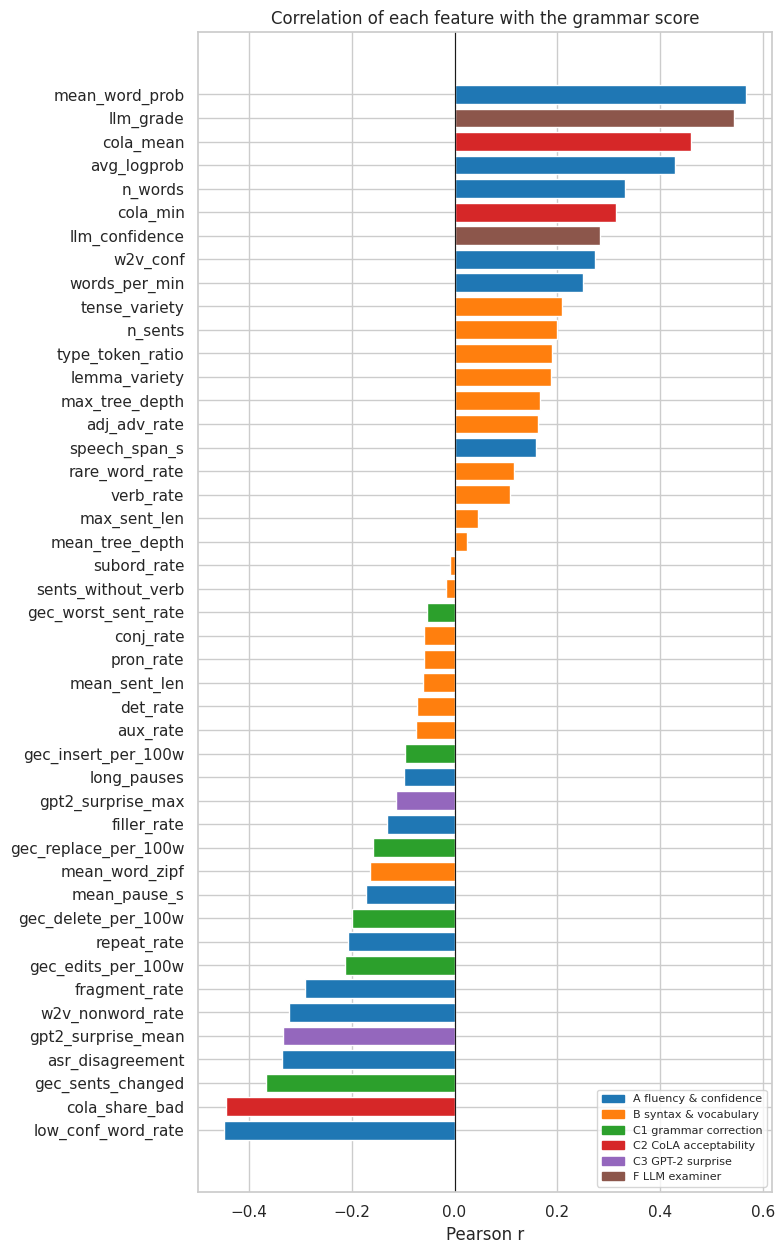

In [21]:
# Which single features track the score? (speech files only)
keep = ~train_df.is_noise.values
corr = X_tab["train"][keep].corrwith(train_df.label[keep]).dropna().sort_values()
gcol = {c: g for g, cols in GROUPS.items() for c in cols}
pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
fig, ax = plt.subplots(figsize=(8, 0.26 * len(corr) + 1))
ax.barh(corr.index, corr.values, color=[pal[gcol[c]] for c in corr.index]); ax.axvline(0, c="k", lw=.8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in pal.values()], labels=list(pal), loc="lower right", fontsize=8)
ax.set(title="Correlation of each feature with the grammar score", xlabel="Pearson r"); plt.tight_layout(); plt.show()

## 6. Model

**Two levels ("stacking"):**
1. **Level 1:** for each embedding block, an **SVR** (support vector regression: fits a smooth curve and ignores errors below a small margin) predicts the score. Each block shrinks from 768-1280 columns to one number. (v1-v2 used Ridge here; on the same CV folds SVR was clearly better, 0.512 to 0.495, because the link between sound and score is not a straight line.) These predictions are made *out-of-fold* (each row predicted by a model that never saw it), so level 2 never sees leaked answers.
2. **Level 2:** tabular features + the embedding predictions go into two different regressors, whose predictions are **averaged**:
   * **LightGBM**: many small decision trees ("if correction rate > 4 and pauses > 6 …"); captures non-linear effects and interactions.
   * **Ridge**: a weighted sum with a penalty against extreme weights; linear and stable.
   Averaging models that make different kinds of mistakes reduces the error. (An SVR at this level was dropped in v3: it added nothing once level 1 used SVRs.)

**And a deliberately simple alternative:** one SVR on the two big audio embeddings side by side, nothing else. It is reported next to the full model (7.1) and written as `submission_simple.csv`, because it reaches most of the accuracy with a fraction of the machinery.

**Evaluation.** 5-fold cross-validation repeated 3 times with different shuffles, **stratified** by rounded score. The *entire* pipeline (scaling, level-1 stacking, level-2 models) is refit inside every fold, so the held-out fold is truly unseen.

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.model_selection import RepeatedStratifiedKFold, KFold
from sklearn.metrics import mean_squared_error
import lightgbm as lgb

rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))
pear = lambda y, p: float(pearsonr(y, p)[0]) if np.std(p) > 1e-9 else np.nan
ridge = lambda: make_pipeline(SimpleImputer(), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25)))
svr = lambda: make_pipeline(SimpleImputer(), StandardScaler(), SVR(C=1.0, epsilon=0.2))
gbm = lambda: lgb.LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=8, min_child_samples=20,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                                random_state=SEED, verbose=-1)
LEVEL2 = {"lgbm": gbm, "svr": svr, "ridge": ridge}
FINAL_LEARNERS = ("lgbm", "ridge")
level1 = lambda: make_pipeline(StandardScaler(), SVR(C=3, epsilon=0.1))     # per-embedding model (v3: SVR fits curves; Ridge cannot)
from sklearn.decomposition import PCA
win_model = lambda: make_pipeline(StandardScaler(), PCA(256, random_state=SEED), SVR(C=5, epsilon=0.05, cache_size=2000))

class Win:
    # A block whose rows are clips and whose values are (n_windows, d) arrays. Indexing selects clips.
    def __init__(self, arrs): self.a = list(arrs)
    def __len__(self): return len(self.a)
    def __getitem__(self, idx):
        idx = np.asarray(idx)
        if idx.dtype == bool: idx = np.where(idx)[0]
        return Win([self.a[i] for i in idx])
    def stacked(self): return np.vstack(self.a).astype(np.float32), np.repeat(np.arange(len(self.a)), [len(w) for w in self.a])

def fit_block(E, y):
    if isinstance(E, Win):                                     # every window inherits its clip's label
        X, owner = E.stacked(); return win_model().fit(X, y[owner])
    return level1().fit(E, y)

def predict_block(m, E):
    if isinstance(E, Win):                                     # clip prediction = mean over its windows
        X, owner = E.stacked(); p = m.predict(X)
        return np.bincount(owner, weights=p) / np.bincount(owner)
    return m.predict(E)

def join_blocks(a, b):
    return Win(a.a + b.a) if isinstance(a, Win) else np.vstack([a, b])

def stack_columns(emb_blocks, y, tr, ap):
    # Level 1. For each embedding: out-of-fold SVR predictions on rows `tr`, and predictions for rows `ap` from a model fit on all of `tr`.
    cols_tr, cols_ap = [], []
    for E in emb_blocks:
        oof = np.zeros(len(tr))
        for a, b in KFold(5, shuffle=True, random_state=SEED).split(tr):
            oof[b] = predict_block(fit_block(E[tr[a]], y[tr[a]]), E[tr[b]])
        cols_tr.append(oof); cols_ap.append(predict_block(fit_block(E[tr], y[tr]), E[ap]))
    return np.column_stack(cols_tr) if cols_tr else np.zeros((len(tr), 0)), np.column_stack(cols_ap) if cols_ap else np.zeros((len(ap), 0))

def fit_predict(Xt, emb, y, tr, ap, learners, Xt_ap=None, emb_ap=None):
    # Fit the full pipeline on rows `tr`; predict rows `ap` (of the same arrays, or of separate test arrays).
    if Xt_ap is None:
        s_tr, s_ap = stack_columns(emb, y, tr, ap); A, B = Xt[tr], Xt[ap]
        if np.array_equal(tr, ap): s_ap = s_tr          # training-fit score: use the same out-of-fold level-1 columns
    else:  # final model: train rows -> test set
        allE = [join_blocks(e, ea) for e, ea in zip(emb, emb_ap)]
        s_tr, s_ap = stack_columns(allE, np.r_[y, np.zeros(len(Xt_ap))], tr, np.arange(len(y), len(y) + len(Xt_ap)))
        A, B = Xt[tr], Xt_ap
    A, B = np.hstack([A, s_tr]), np.hstack([B, s_ap])
    preds = {k: np.clip(LEVEL2[k]().fit(A, y[tr]).predict(B), 0, 5) for k in learners}
    return np.mean(list(preds.values()), axis=0), preds

def evaluate(name, cols, emb_names, learners=FINAL_LEARNERS, n_rep=3, frame=None, data=None):
    frame = X_tab["train"] if frame is None else frame
    keep, y = data if data is not None else (~train_df.is_noise.values, train_df.label.values)
    Xt = frame[cols].values[keep] if cols else np.zeros((keep.sum(), 0)); y = y[keep]
    emb = [EMB[e][0][keep] for e in emb_names]
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=SEED)
    oof = np.zeros((n_rep, len(y))); fr, fp = [], []
    strata = np.where(y == 0, 0, np.clip(np.round(y), 2, 5))       # score 1 has one file -> merged into 2
    for k, (tr, va) in enumerate(cv.split(np.zeros((len(y), 1)), strata)):
        p, _ = fit_predict(Xt, emb, y, tr, va, learners)
        oof[k // 5, va] = p; fr.append(rmse(y[va], p)); fp.append(pear(y[va], p))
    p_tr, _ = fit_predict(Xt, emb, y, np.arange(len(y)), np.arange(len(y)), learners)   # training fit (optimistic)
    return dict(model=name, cv_rmse=np.mean(fr), cv_rmse_sd=np.std(fr), cv_pearson=np.mean(fp), cv_pearson_sd=np.std(fp),
                train_rmse=rmse(y, p_tr), train_pearson=pear(y, p_tr)), oof.mean(0)

def evaluate_simple(name, emb_names, n_rep=3):
    # The SIMPLE model: one SVR on the audio embeddings placed side by side. No stacking, no hand-built features.
    keep = ~train_df.is_noise.values; y = train_df.label.values[keep]
    X = EMB[emb_names[0]][0][keep] if len(emb_names) == 1 else np.hstack([EMB[e][0][keep] for e in emb_names])
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=SEED)
    oof = np.zeros((n_rep, len(y))); fr, fp = [], []
    for k, (tr, va) in enumerate(cv.split(np.zeros((len(y), 1)), np.clip(np.round(y), 2, 5))):
        p = np.clip(predict_block(fit_block(X[tr], y[tr]), X[va]), 0, 5)
        oof[k // 5, va] = p; fr.append(rmse(y[va], p)); fp.append(pear(y[va], p))
    m = fit_block(X, y); p_tr = np.clip(predict_block(m, X), 0, 5)
    return dict(model=name, cv_rmse=np.mean(fr), cv_rmse_sd=np.std(fr), cv_pearson=np.mean(fp), cv_pearson_sd=np.std(fp),
                train_rmse=rmse(y, p_tr), train_pearson=pear(y, p_tr)), oof.mean(0), m

### 6.1 Which layer of the new audio models knows most about grammar?
For each saved layer: a Ridge regression on that layer alone, scored by 5-fold CV. The curve shows *where* in each network grammar-relevant information lives: it peaks in the upper-middle layers of WavLM-large and in the last layers of the Whisper encoder (which feed its text decoder).
Rather than picking the single best layer (which would tune to these folds), each model contributes the **average of a fixed band of layers** (shaded): WavLM-large layers 16-24 and Whisper encoder layers 28-32, the upper part of each network.

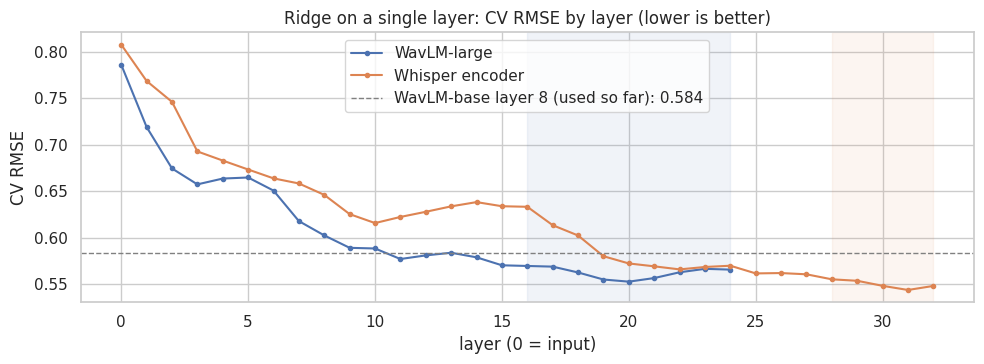

,layer,rmse,pearson
model,,,
WavLM-large,20,0.553,0.835
Whisper encoder,31,0.544,0.842


embedding blocks: ['D1 Whisper-text embedding', 'D2 wav2vec2-text embedding', 'E WavLM audio embedding', 'E2 WavLM-large (layers 16-24)', 'E3 Whisper encoder (layers 28-32)', 'W 10 s windows (WavLM-large + Whisper enc)']


In [23]:
def layer_curve(block, name):
    keep = ~train_df.is_noise.values; y = train_df.label.values[keep]
    L = block["train"].shape[1]; strata = np.clip(np.round(y), 2, 5)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED + 1)   # different shuffle from the main CV
    out = []
    for l in range(L):
        X = block["train"][keep, l].astype(np.float32); p = np.zeros(len(y))
        for tr, va in cv.split(X, strata): p[va] = ridge().fit(X[tr], y[tr]).predict(X[va])
        out.append(dict(model=name, layer=l, rmse=rmse(y, np.clip(p, 0, 5)), pearson=pear(y, p)))
    return pd.DataFrame(out)

curves = [layer_curve(b, n) for n, b in [("WavLM-large", WAVL), ("Whisper encoder", WENC)] if b is not None]
if curves:
    curves = pd.concat(curves, ignore_index=True)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for n, g in curves.groupby("model"): ax.plot(g.layer, g.rmse, marker="o", ms=3, label=n)
    if WAV is not None:
        base_rmse = layer_curve({"train": WAV["train"][:, None, :]}, "WavLM-base L8").rmse.iloc[0]
        ax.axhline(base_rmse, c="gray", ls="--", lw=1, label=f"WavLM-base layer 8 (used so far): {base_rmse:.3f}")
    ax.axvspan(16, 24, alpha=.08, color="C0"); ax.axvspan(28, 32, alpha=.08, color="C1")
    ax.set(title="Ridge on a single layer: CV RMSE by layer (lower is better)", xlabel="layer (0 = input)", ylabel="CV RMSE"); ax.legend()
    plt.tight_layout(); plt.show()
    display(curves.loc[curves.groupby("model").rmse.idxmin()].set_index("model").round(3))
if WAVL is not None:
    EMB["E2 WavLM-large (layers 16-24)"] = tuple(WAVL[s][:, 16:25].astype(np.float32).mean(1) for s in ("train", "test"))
if WENC is not None:
    EMB["E3 Whisper encoder (layers 28-32)"] = tuple(WENC[s][:, 28:33].astype(np.float32).mean(1) for s in ("train", "test"))
if WINS is not None:
    EMB["W 10 s windows (WavLM-large + Whisper enc)"] = (Win(WINS["train"]), Win(WINS["test"]))
print("embedding blocks:", list(EMB))

## 7. Results
### 7.1 From simple to full model

In [24]:
ALL_TAB = [c for g in GROUPS.values() for c in g]
ALL_EMB = list(EMB)
y_speech = train_df.label.values[~train_df.is_noise.values]

base = dict(model="mean predictor", cv_rmse=float(np.std(y_speech)), cv_pearson=np.nan)   # always predicts the average
runs = [
    ("baseline: fluency + Whisper embedding (Ridge)", GROUPS["A fluency & confidence"], ["D1 Whisper-text embedding"] if "D1 Whisper-text embedding" in EMB else [], ("ridge",)),
    ("A + B handcrafted (LightGBM)", GROUPS["A fluency & confidence"] + GROUPS["B syntax & vocabulary"], [], ("lgbm",)),
    ("all tabular A–C (LightGBM)", ALL_TAB, [], ("lgbm",)),
    ("all tabular + embeddings (LightGBM)", ALL_TAB, ALL_EMB, ("lgbm",)),
    ("all tabular + embeddings (Ridge)", ALL_TAB, ALL_EMB, ("ridge",)),
    ("FINAL: all features, LightGBM+Ridge average", ALL_TAB, ALL_EMB, FINAL_LEARNERS),
]
rows, OOF = [base], {}
AUDIO_PAIR = [e for e in EMB if e[:2] in ("E2", "E3")]
WIN_KEY = [e for e in EMB if e.startswith("W ")]
if len(AUDIO_PAIR) == 2:
    t0 = time.time(); res, _, _ = evaluate_simple("one SVR on whole-clip WavLM-large + Whisper encoder", AUDIO_PAIR); rows.append(res)
    print(f"{res['model']:55s} CV RMSE {res['cv_rmse']:.3f}  r {res['cv_pearson']:.3f}   ({time.time()-t0:.0f}s)")
SIMPLE_KEYS = WIN_KEY or AUDIO_PAIR
if SIMPLE_KEYS:
    t0 = time.time(); res, OOF["SIMPLE"], SIMPLE_MODEL = evaluate_simple("SIMPLE: one SVR on 10 s windows, clip = mean" if WIN_KEY else "SIMPLE: one SVR on WavLM-large + Whisper encoder", SIMPLE_KEYS); rows.append(res)
    print(f"{res['model']:55s} CV RMSE {res['cv_rmse']:.3f}  r {res['cv_pearson']:.3f}   ({time.time()-t0:.0f}s)")
for name, cols, emb, lr in runs:
    t0 = time.time(); res, OOF[name] = evaluate(name, cols, emb, lr); rows.append(res)
    print(f"{name:55s} CV RMSE {res['cv_rmse']:.3f}  r {res['cv_pearson']:.3f}   ({time.time()-t0:.0f}s)")
results = pd.DataFrame(rows).set_index("model")
FINAL = runs[-1][0]
display(results.round(3))

one SVR on whole-clip WavLM-large + Whisper encoder     CV RMSE 0.507  r 0.869   (9s)
SIMPLE: one SVR on 10 s windows, clip = mean            CV RMSE 0.509  r 0.866   (160s)
baseline: fluency + Whisper embedding (Ridge)           CV RMSE 0.697  r 0.728   (12s)
A + B handcrafted (LightGBM)                            CV RMSE 0.717  r 0.709   (3s)
all tabular A–C (LightGBM)                              CV RMSE 0.682  r 0.741   (3s)
all tabular + embeddings (LightGBM)                     CV RMSE 0.497  r 0.873   (709s)
all tabular + embeddings (Ridge)                        CV RMSE 0.501  r 0.871   (708s)
FINAL: all features, LightGBM+Ridge average             CV RMSE 0.488  r 0.877   (707s)


,cv_rmse,cv_pearson,cv_rmse_sd,cv_pearson_sd,train_rmse,train_pearson
model,,,,,,
mean predictor,1.014,NaN,NaN,NaN,NaN,NaN
one SVR on whole-clip WavLM-large + Whisper encoder,0.507,0.869,0.029,0.015,0.093,0.997
"SIMPLE: one SVR on 10 s windows, clip = mean",0.509,0.866,0.035,0.019,0.033,1.000
baseline: fluency + Whisper embedding (Ridge),0.697,0.728,0.032,0.030,0.682,0.740
A + B handcrafted (LightGBM),0.717,0.709,0.029,0.029,0.400,0.928
all tabular A–C (LightGBM),0.682,0.741,0.040,0.036,0.359,0.942
all tabular + embeddings (LightGBM),0.497,0.873,0.026,0.015,0.263,0.967
all tabular + embeddings (Ridge),0.501,0.871,0.026,0.014,0.480,0.882
"FINAL: all features, LightGBM+Ridge average",0.488,0.877,0.025,0.014,0.364,0.936


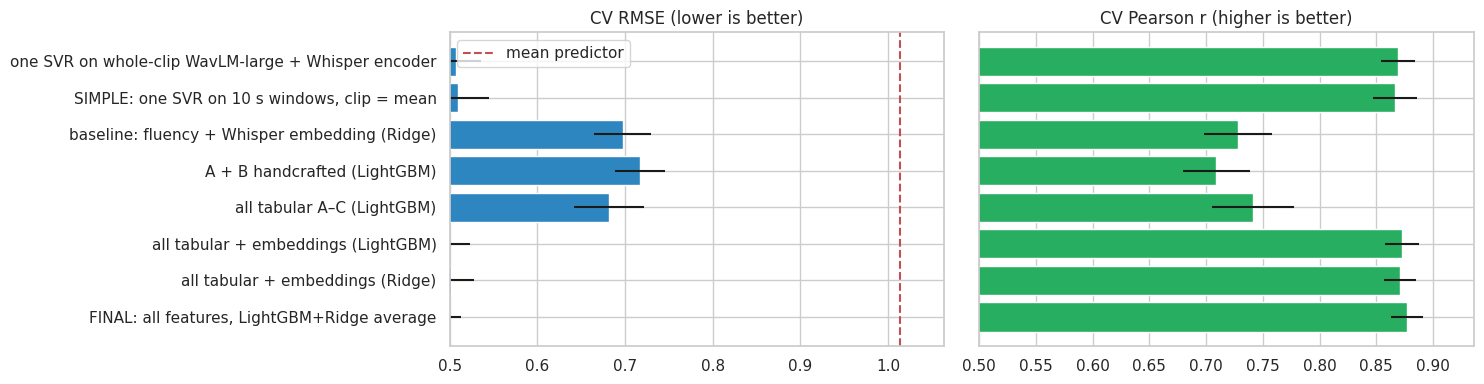

In [25]:
r = results.drop(index="mean predictor")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].barh(r.index, r.cv_rmse, xerr=r.cv_rmse_sd, color="#2e86c1"); ax[0].axvline(base["cv_rmse"], c="r", ls="--", label="mean predictor")
ax[0].set(title="CV RMSE (lower is better)", xlim=(0.5, None)); ax[0].legend(); ax[0].invert_yaxis()
ax[1].barh(r.index, r.cv_pearson, xerr=r.cv_pearson_sd, color="#27ae60"); ax[1].set(title="CV Pearson r (higher is better)", xlim=(0.5, None))
ax[1].set_yticklabels([]); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

### 7.2 Where the model is right and wrong

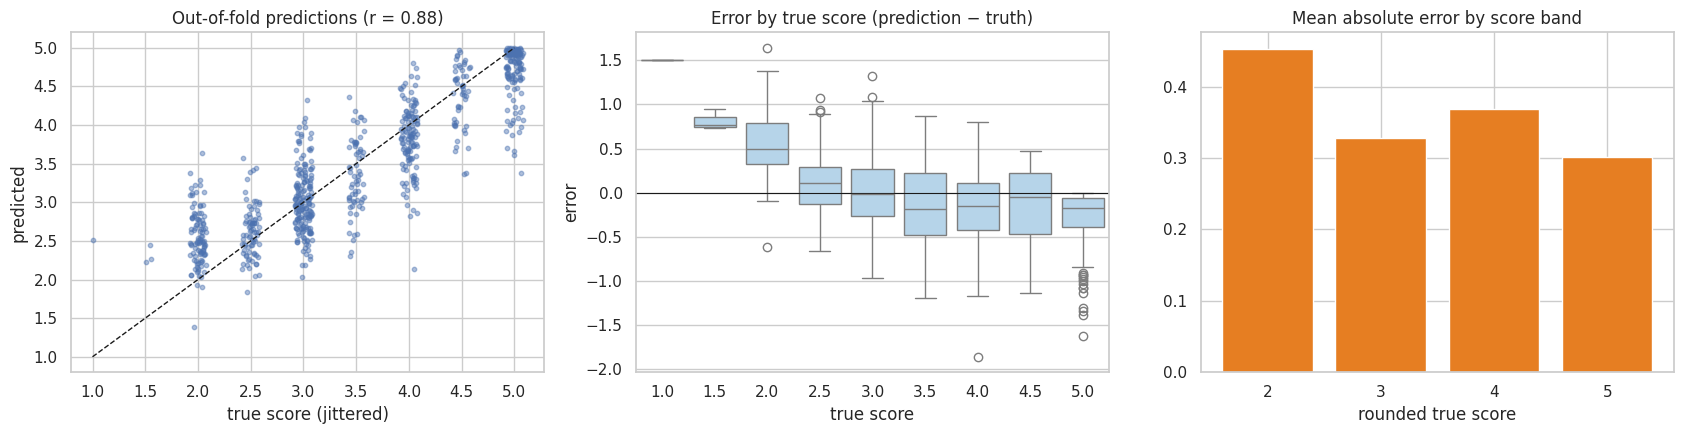

In [26]:
y, p = y_speech, OOF[FINAL]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y + np.random.uniform(-.08, .08, len(y)), p, s=10, alpha=.45); ax[0].plot([1, 5], [1, 5], "k--", lw=1)
ax[0].set(title=f"Out-of-fold predictions (r = {pear(y, p):.2f})", xlabel="true score (jittered)", ylabel="predicted")
sns.boxplot(x=y, y=p - y, ax=ax[1], color="#aed6f1"); ax[1].axhline(0, c="k", lw=.8)
ax[1].set(title="Error by true score (prediction − truth)", xlabel="true score", ylabel="error")
err = pd.Series(np.abs(p - y)).groupby(np.round(y).clip(2, 5)).mean()
ax[2].bar(err.index.astype(int).astype(str), err.values, color="#e67e22"); ax[2].set(title="Mean absolute error by score band", xlabel="rounded true score")
plt.tight_layout(); plt.show()

In [27]:
# The five largest misses, with what was said. Useful for spotting label noise vs. model blind spots.
sp = train_df[~train_df.is_noise].reset_index(drop=True).assign(pred=p, err=p - y)
for r in sp.reindex(sp.err.abs().sort_values(ascending=False).index).head(5).itertuples():
    print(f"── {r.filename}: true {r.label}, predicted {r.pred:.2f}\n   {r.text[:350]}\n")

── audio_238.wav: true 4.0, predicted 2.14
   The playground has many children. There are many sl- there are slides, seesaw, and different kind of playing, playing activities. The noise from the playground are coming from the children shouting and playing.

── audio_128.wav: true 2.0, predicted 3.64
   Staying at a resort is a relaxing and enjoyable experience. When you arrive, you check into a beautiful room. With the comfortable- the comfortable beds and nice view, you can spend your days walking by the pool, enjoying delicious meals at the resort restaurants. friends. Talking apart is fun. Activities like spa, treatments, sports, outreach are 

── audio_555.wav: true 5.0, predicted 3.38
   I'm gonna describe the scene of a cloud- crowded market, um, uh, uh, there is a market nearby, uh, where I live, and, uh, I mostly go to the market for some food or to buy some groceries or some items, and that market, uh, is mostly crowded in the evening, uh, as, uh, most of the people are outsid

**Reading the largest misses.** Two recurring patterns:
* **Fluent-sounding but rated low.** Several over-predicted speakers deliver polished, generic passages ("a hobby is considered as a regular activity that is done for enjoyment during leisure time"). They read like memorised or prepared text. The rubric's lowest band explicitly mentions *"memorized sentence patterns"*, so raters penalise this, but surface fluency fools the model.
* **Disfluent but rated high.** Some under-predicted speakers restart sentences often ("it was- it was a big…") yet are rated 5. The rubric rewards speakers who *"correct themselves when necessary"*, so raters do not penalise self-repair, while the model reads it as hesitation.

Both point to the same limitation: telling *spontaneous control of grammar* apart from *delivery* needs features about spontaneity (topic-specificity, repeated stock phrases) that this pipeline does not have.

### 7.3 Ablation: what each feature group contributes
Starting from the final model, one group is removed at a time and the CV is rerun. The bigger the jump in error, the more that group mattered *given all the others*. (Groups that overlap with others can look unimportant here even though they are informative alone.)

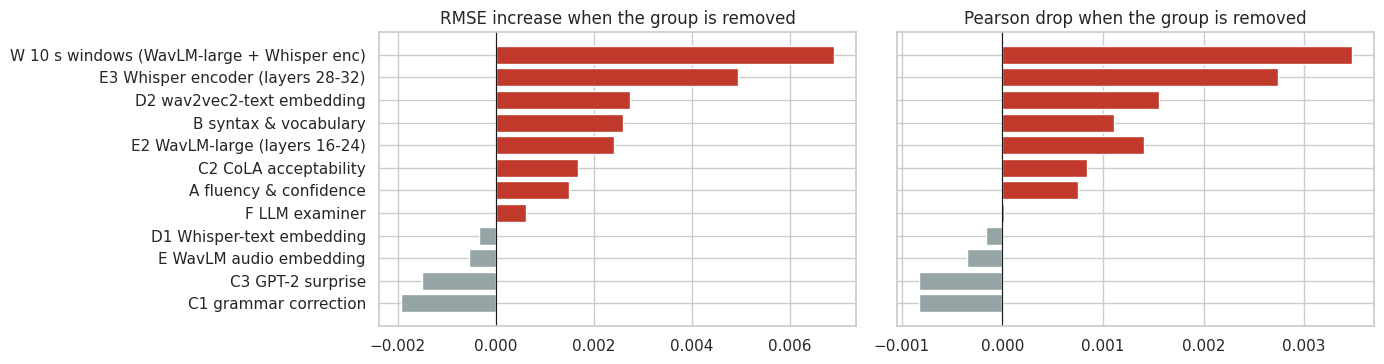

,group,d_rmse,d_pearson
11,W 10 s windows (WavLM-large + Whisper enc),0.0069,-0.0035
10,E3 Whisper encoder (layers 28-32),0.0049,-0.0027
7,D2 wav2vec2-text embedding,0.0027,-0.0016
1,B syntax & vocabulary,0.0026,-0.0011
9,E2 WavLM-large (layers 16-24),0.0024,-0.0014
3,C2 CoLA acceptability,0.0017,-0.0008
0,A fluency & confidence,0.0015,-0.0007
5,F LLM examiner,0.0006,-0.0000
6,D1 Whisper-text embedding,-0.0003,0.0002
8,E WavLM audio embedding,-0.0006,0.0004


In [28]:
abl = []
full = pd.Series(evaluate("full, 1 repeat", ALL_TAB, ALL_EMB, n_rep=1)[0])   # same single repeat as the ablations
for g in list(GROUPS) + list(EMB):
    cols = [c for c in ALL_TAB if c not in GROUPS.get(g, [])]; emb = [e for e in ALL_EMB if e != g]
    res, _ = evaluate(f"without {g}", cols, emb, n_rep=1)       # 1 repeat: window SVRs make each run slow
    abl.append(dict(group=g, d_rmse=res["cv_rmse"] - full.cv_rmse, d_pearson=res["cv_pearson"] - full.cv_pearson))
abl = pd.DataFrame(abl).sort_values("d_rmse", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].barh(abl.group, abl.d_rmse, color=["#c0392b" if v > 0 else "#95a5a6" for v in abl.d_rmse]); ax[0].axvline(0, c="k", lw=.8)
ax[0].set(title="RMSE increase when the group is removed"); ax[0].invert_yaxis()
ax[1].barh(abl.group, -abl.d_pearson, color=["#c0392b" if v < 0 else "#95a5a6" for v in abl.d_pearson]); ax[1].axvline(0, c="k", lw=.8)
ax[1].set(title="Pearson drop when the group is removed"); ax[1].set_yticklabels([]); ax[1].invert_yaxis()
plt.tight_layout(); plt.show(); display(abl.round(4))

**What the ablation shows** (one CV repeat per row, so differences under about 0.01 are within noise):
* **No single block is indispensable any more.** With five audio-based blocks (WavLM-base, WavLM-large, Whisper encoder, 10 s windows, wav2vec2 text), removing any one costs at most about 0.007 RMSE, because the others carry much the same information. In v1, when WavLM-base was the *only* audio block, removing it cost about 0.08 (0.54 → 0.61).
* **The audio side as a whole carries the model.** Hand-built tabular features alone reach about 0.68; adding the embeddings brings the model to about 0.49. The blocks that help most here are the 10 s windows, the Whisper encoder and WavLM-large.
* **Text-based grammar features change RMSE by less than 0.003 each.** That does not mean they carry no signal: their information **overlaps** with what the audio already captures. They are kept because they make the model explainable in rubric terms (7.5).
* **The LLM examiner (F) adds almost nothing.** Its grades cluster between 3 and 4 (correlation 0.54 with the human score, weaker than the audio models), so the regressor learns to rely on it little.
* Interpretation: the raters' *grammar* score is strongly entangled with overall spoken proficiency (pronunciation, fluency, prosody), which is why models of how the speech *sounds* predict it so well.
* Groups whose removal slightly *improves* RMSE were deliberately **not** dropped: the gain is within noise, and choosing features by peeking at the same CV folds would make the reported score optimistic.

### 7.4 Why the 37 noise files were excluded

In [29]:
res_noise, _ = evaluate("final model, trained & tested WITH noise files", ALL_TAB, ALL_EMB, n_rep=1,
                        data=(np.ones(len(train_df), bool), train_df.label.values))
display(pd.DataFrame([results.loc[FINAL, ["cv_rmse", "cv_pearson"]].rename("excluded (used)"),
                      pd.Series(res_noise)[["cv_rmse", "cv_pearson"]].rename("included")]).astype(float).round(3))
print("With the noise files in, part of the measured skill is telling static from speech, which the test set never needs.")

,cv_rmse,cv_pearson
excluded (used),0.488,0.877
included,0.482,0.921


With the noise files in, part of the measured skill is telling static from speech, which the test set never needs.


### 7.5 Interpretability: what drives individual predictions (SHAP)
SHAP splits each prediction into contributions from each feature. Below: the LightGBM part of the final model, fit on all speech files. Each dot is one file; red = high feature value, blue = low; right of zero = pushes the score up.

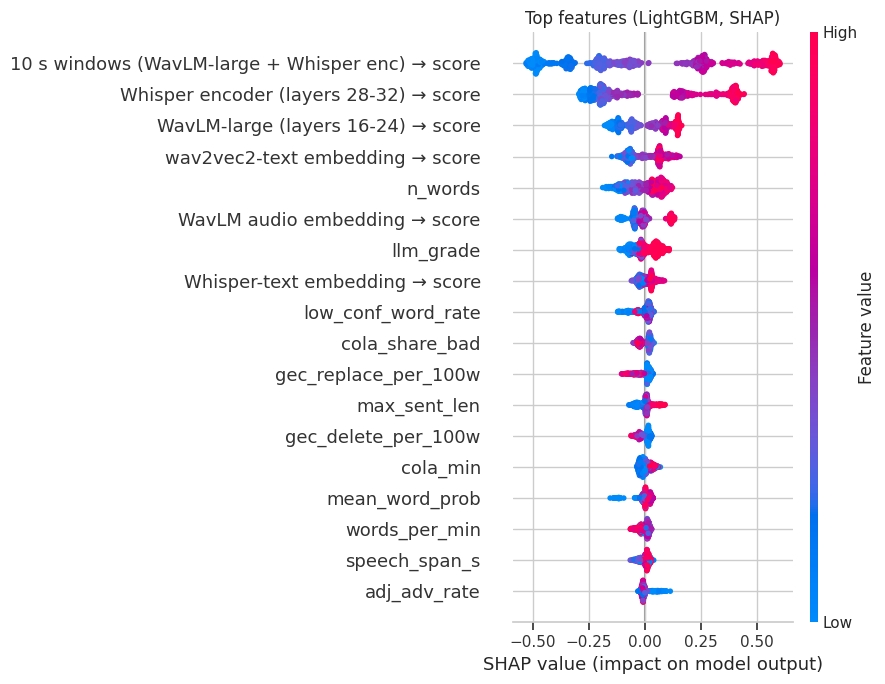

In [30]:
import shap
keep = ~train_df.is_noise.values; idx = np.arange(keep.sum())
emb = [EMB[e][0][keep] for e in ALL_EMB]
s_tr, _ = stack_columns(emb, y_speech, idx, idx[:1])
names = ALL_TAB + [e.split(" ", 1)[1] + " → score" for e in ALL_EMB]
A = pd.DataFrame(np.hstack([X_tab["train"][ALL_TAB].values[keep], s_tr]), columns=names)
g = gbm().fit(A, y_speech)
sv = shap.TreeExplainer(g).shap_values(A)
shap.summary_plot(sv, A, max_display=18, show=False, plot_size=(9, 7)); plt.title("Top features (LightGBM, SHAP)"); plt.tight_layout(); plt.show()

## 8. Final model → test predictions

correlation between full and simple test predictions: 0.975


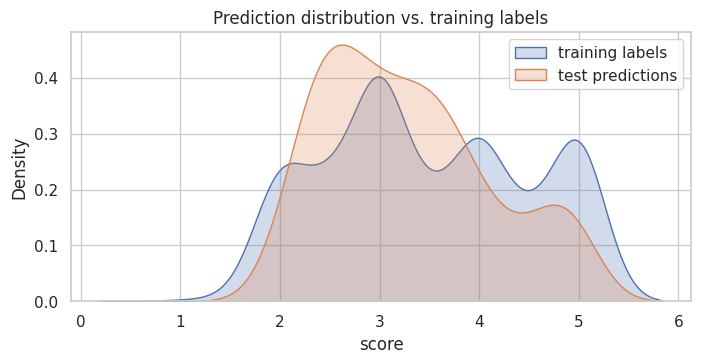

count    216.00
mean       3.28
std        0.83
min        1.96
25%        2.58
50%        3.17
75%        3.77
max        4.99


In [31]:
keep = ~train_df.is_noise.values
Xt, y = X_tab["train"][ALL_TAB].values[keep], y_speech
emb_tr = [EMB[e][0][keep] for e in ALL_EMB]; emb_te = [EMB[e][1] for e in ALL_EMB]
pred, parts = fit_predict(Xt, emb_tr, y, np.arange(len(y)), None, FINAL_LEARNERS,
                          Xt_ap=X_tab["test"][ALL_TAB].values, emb_ap=emb_te)
pred[test_df.is_noise.values] = 0.0               # safety net (expected: 0 files)

sub = pd.DataFrame({"filename": test_df.filename, "label": np.round(pred, 4)})
assert sub.filename.tolist() == pd.read_csv(DATA / "test.csv").filename.tolist() and sub.label.between(0, 5).all()
sub.to_csv(WORK / "submission.csv", index=False)
if SIMPLE_KEYS:                                    # the simple model's predictions, kept as a separate file
    Xs = EMB[SIMPLE_KEYS[0]][1] if len(SIMPLE_KEYS) == 1 else np.hstack([EMB[e][1] for e in SIMPLE_KEYS])
    p_simple = np.clip(predict_block(SIMPLE_MODEL, Xs), 0, 5)
    pd.DataFrame({"filename": test_df.filename, "label": np.round(p_simple, 4)}).to_csv(WORK / "submission_simple.csv", index=False)
    print("correlation between full and simple test predictions:", round(np.corrcoef(pred, p_simple)[0, 1], 3))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.kdeplot(y, label="training labels", ax=ax, fill=True); sns.kdeplot(pred, label="test predictions", ax=ax, fill=True)
ax.set(title="Prediction distribution vs. training labels", xlabel="score"); ax.legend(); plt.show()
print(sub.label.describe().round(2).to_string())

## 9. Report: results summary

In [32]:
f = results.loc[FINAL]; b = results.loc[runs[0][0]]
display(Markdown(f'''
| Metric | Final model | Phase-1 baseline | Mean predictor |
|---|---|---|---|
| **Training RMSE** (required; fit and scored on the same 732 files, optimistic) | **{f.train_rmse:.3f}** | {b.train_rmse:.3f} | — |
| Training Pearson | {f.train_pearson:.3f} | {b.train_pearson:.3f} | — |
| **CV RMSE** (5-fold × 3, honest estimate) | **{f.cv_rmse:.3f} ± {f.cv_rmse_sd:.3f}** | {b.cv_rmse:.3f} | {base["cv_rmse"]:.3f} |
| **CV Pearson** | **{f.cv_pearson:.3f} ± {f.cv_pearson_sd:.3f}** | {b.cv_pearson:.3f} | — |
'''))
print(f"TRAINING RMSE: {f.train_rmse:.4f}")
results.to_csv(WORK / "cv_results.csv"); abl.to_csv(WORK / "ablation.csv", index=False)


| Metric | Final model | Phase-1 baseline | Mean predictor |
|---|---|---|---|
| **Training RMSE** (required; fit and scored on the same 732 files, optimistic) | **0.364** | 0.682 | — |
| Training Pearson | 0.936 | 0.740 | — |
| **CV RMSE** (5-fold × 3, honest estimate) | **0.488 ± 0.025** | 0.697 | 1.014 |
| **CV Pearson** | **0.877 ± 0.014** | 0.728 | — |


TRAINING RMSE: 0.3644


### Approach, recap
1. **Quality control** found 37 noise-only recordings (all score 0, none in test) → excluded, with the impact measured (7.4).
2. **Light preprocessing:** 16 kHz mono, 70 Hz high-pass, loudness normalisation; silence handled by VAD so pauses stay measurable.
3. **Transcription chosen by experiment:** Whisper large-v3 with a verbatim prompt keeps fillers and real grammar errors; wav2vec2 garbles more, so it serves as an intelligibility signal rather than the main transcript.
4. **Interpretable features** mapped to the rubric (fluency, syntactic complexity, error-correction density, acceptability, surprise), plus text and audio embeddings condensed by stacking.
5. **Small-data modelling:** frozen pretrained models; per-embedding SVRs stacked under an averaged LightGBM + Ridge, evaluated with leak-free repeated stratified CV. A one-SVR audio-only model is reported alongside as the simple baseline.

### Limitations & next steps
* **ASR is the ceiling.** Every text feature inherits transcription errors; Whisper still tidies some disfluencies. A grammar scorer trained on disfluent learner speech (or fine-tuning Whisper for verbatim output) would help most.
* **The strongest signal is acoustic, not grammatical.** WavLM and the ASR-confidence features capture pronunciation and fluency, which correlate with the grammar score in this data. On a population with different accents, or where grammar and pronunciation diverge (fluent speakers with poor grammar), this correlation could weaken.
* **Possible shortcut via recording conditions.** An audio embedding can also pick up microphone and room characteristics. If recordings were collected in batches that differ in typical score, part of its accuracy could come from that. A cross-validation that holds out whole recording batches would test this; batch information is not available here.
* **Memorised answers and self-correction** are the main sources of large errors (7.2).
* **The bottom of the scale is under-represented** (4 files below 2); predictions compress toward the middle (7.2). More low-score data or a calibration step mapping predictions back to the label distribution would address it.
* **Label noise:** the largest misses (7.2) include transcripts whose grammar looks better or worse than the score, suggesting rater disagreement sets a floor on achievable error.
* **Tried and found not to help (kept in for transparency):** an LLM examiner reading the transcript (v3; too timid, grades cluster at 3-4); training on 10 s windows *alone* instead of whole clips (no better on its own, but useful inside the ensemble).
* **Checked and ruled out:** train and test reuse file numbers, but same-numbered files are different speakers (their audio embeddings are no more similar than random pairs, and labels do not correlate), so there is no speaker leak to exploit.
* **Not tried:** fine-tuning a speech model end-to-end (likely the biggest remaining gain, but costly and easy to overfit with 732 clips); an audio-capable frontier model as a judge.

### Iteration log
| Version | Change | CV RMSE | CV Pearson |
|---|---|---|---|
| v1 | Whisper + wav2vec2 transcripts, 43 features, WavLM-base and text embeddings, averaged LightGBM/SVR/Ridge | 0.537 | 0.850 |
| v2 | + WavLM-large and Whisper-encoder audio embeddings | 0.513 | 0.864 |
| v3 | + LLM examiner; SVR instead of Ridge for each embedding; LightGBM + Ridge at level 2 | 0.495 | 0.874 |
| v4 (this notebook) | + 10 s window embeddings with a window-level SVR | **0.488** | **0.877** |

The **SIMPLE** model (one SVR on WavLM-large + Whisper-encoder clip embeddings, no hand-built features) reaches 0.507 / 0.869: most of the accuracy with a fraction of the machinery.